# WNMFDDA — New rejection hypotheses RH1, RH2, RH3 (Kaggle notebook)

Evidence notebook for three new rejection hypotheses about *WNMFDDA* (Wang et al., J Transl Med 2022). Each hypothesis uses the same **E / P / Q / V / L** framework as the earlier notebooks:

| Part | Meaning |
|---|---|
| **E** | Equations and assumptions |
| **P** | Proposition (falsifiable claim) |
| **Q** | Quantities and the decision rule, fixed *before* running |
| **V** | Verification (reproducible code on Fdataset and Cdataset) |
| **L** | Link to predictive consequences and what the result would mean |

| ID | Rejection statement |
|---|---|
| **RH1** | The cold-start claim fails: the paper says WKNN lets the model work for new drugs and diseases, but in practice that transfer is weak. |
| **RH2** | The advantage collapses as data gets sparser: WNMFDDA's edge over simple methods needs the benchmark's density. |
| **RH3** | Most of the lift is neighbour evidence that a training-free method recovers. |

**Decision rules (as supplied; applied to seed-level paired means)**

| Hypothesis | SUPPORTED if | FALSIFIED if |
|---|---|---|
| RH1 (per axis, per dataset) | warm-to-cold AUC drop ≥ 0.10 **and** the lower 95 % bound of the cold margin over the best of {disease/drug popularity, dev-tuned kNN} is below 0.05 | cold AUC within 0.05 of warm, **or** the margin is clearly above 0.05 (lower 95 % bound > 0.05) |
| RH2 | AUC(25 % of positives) is ≥ 0.10 below AUC(100 %) **and** the gain over the best baseline at the sparsest density is below δ = 0.01 | the gain stays above δ at every density |
| RH3 | a dev-tuned training-free method recovers ≥ 70 % of WNMFDDA's lift over popularity **and** sits < 0.06 AUC below WNMFDDA | no simple method (incl. truncated SVD and graph diffusion) gets within 0.06 |

Each verdict is printed twice: **as stated** (point estimates, with the CI used where the rule names one) and **strict** (95 % intervals on both conditions). A case that fits neither rule is reported as INCONCLUSIVE.

**How to run on Kaggle.** Attach the Kaggle Dataset that holds `DataF.mat` and `DataC.mat` (default folder `/kaggle/input/datasets/cliffbooth/drug-disease-association`; the loader falls back to a recursive search of `/kaggle/input`). Choose `PROFILE` in the config cell: `smoke` (minutes, sanity check), `quick` (default: 5 seeds × 5 folds), `full` (20 seeds × 10 folds, many hours). Results are checkpointed to CSV, so a restarted session resumes where it stopped. CPU is enough.

**Shared validity protocol**
1. Held-out labels are removed from the matrix *before* WKNN, similarity-weighted baselines, and factorization.
2. Negatives are *all unobserved pairs*, not verified negatives. Pooled ROC-AUC is the primary metric.
3. Every method sees identical splits and identical candidate pairs. Baselines are tuned on an inner dev split of the **training** matrix only; WNMFDDA uses the paper's parameters (p = K = 5, a = 0.5, k = 160, λ = 1, β = 0.02).
4. The paper tuned those parameters on these same datasets, which favours WNMFDDA relative to the dev-tuned baselines. That bias works *against* all three rejection hypotheses.
5. p-values are **directional**: for every primary test *a small p-value means the rejection hypothesis is supported*. Each primary test is an intersection–union test of the rule's two conditions (p = larger of the two one-sided p-values), corrected with Holm over all primary tests.
6. Seed intervals reflect split and initialisation randomness on two fixed datasets, not generalisation to other data.

**Documented deviations from the official code**
* **Eligible neighbours.** WKNN and kNN pick their top-*K* neighbours only among entities with at least one known training association (`ELIG = True`). This matters only when profiles are empty (cold start, very sparse data) and simulates one new entity arriving at a time. Set `ELIG = False` for the literal behaviour.
* **Initialisation and stopping.** Factors start from a non-negative random matrix scaled to the mean of the target; stopping uses the official column-change rule (`1e-4`) with an iteration cap `MAX_ITER`. A convergence audit below shows how AUC depends on that cap.
* **Graph weights** follow the published equation (the undefined `Clu_mat` in `Graph.m` is not invented).

In [1]:
import os, sys, time, glob, warnings
from types import SimpleNamespace as NS
import numpy as np, pandas as pd, scipy.io as sio
from scipy import stats
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)
try:
    from IPython.display import display
except Exception:
    display = print
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 160)

# ------------------------------ CONFIG ------------------------------
PROFILE = os.environ.get("WNMFDDA_PROFILE", "quick")          # 'smoke' | 'quick' | 'full'
PROFILES = {
    "smoke": dict(N_SEEDS=2,  N_FOLDS=3,  MAX_ITER=30,  WARM_PARTS=1, DENS=[1.0, 0.25, 0.05]),
    "quick": dict(N_SEEDS=5,  N_FOLDS=5,  MAX_ITER=200, WARM_PARTS=2, DENS=[1.0, 0.5, 0.25, 0.10, 0.05]),
    "full":  dict(N_SEEDS=20, N_FOLDS=10, MAX_ITER=500, WARM_PARTS=3, DENS=[1.0, 0.5, 0.25, 0.10, 0.05]),
}
globals().update(PROFILES[PROFILE])
SEEDS = list(range(N_SEEDS))
WARM_SPLIT = 5                                                # RH1: held-out entities' positives are split into 5 parts for the warm reference

PAPER = dict(p=5, K=5, a=0.5, k=160, lam=1.0, beta=0.02)
ELIG = True                                                   # neighbours restricted to entities with >= 1 training association
DATA_DIR = os.environ.get("DATA_DIR", "/kaggle/input/datasets/cliffbooth/drug-disease-association")
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
RES_PATH = os.path.join(OUT_DIR, f"wnmfdda_rh_results_{PROFILE}.csv")
FORCE_RERUN = False

# decision-rule constants (fixed before running)
DELTA = 0.01; ALPHA = 0.05
RH1_DROP_MIN, RH1_DROP_FALSIFY, RH1_MARGIN = 0.10, 0.05, 0.05
RH2_DROP_MIN = 0.10
RH3_LIFT_MIN, RH3_GAP_MAX = 0.70, 0.06

# dev-tuning grids for the training-free baselines (tuned on an inner split of the TRAINING matrix only)
KNN_K = [1, 3, 5, 10, 20, 50, 100]; KNN_G = [1.0, 4.0]
DIFF_L = [0.3, 1.0, 3.0, 10.0, 30.0]
SVD_K = [10, 20, 40, 80, 160]

RES = pd.read_csv(RES_PATH) if (os.path.exists(RES_PATH) and not FORCE_RERUN) else pd.DataFrame()
PRIMARY, VERDICT = {}, {}

# user-supplied pilot numbers (dataset not stated; Fdataset-like). Printed next to this run for comparison only.
PILOT = dict(
    RH1=dict(LDO=dict(W1G1=0.788, warm=0.919, POP=0.734, KNN=0.765), LDiO=dict(W1G1=0.738, KNN=0.699)),
    RH2={1.0: (0.919, 0.054), 0.5: (0.851, 0.059), 0.25: (0.758, 0.046), 0.10: (0.648, 0.028), 0.05: (0.559, 0.004)},
    RH3=dict(sup_pos=0.64, sup_neg=0.06, W1G1_sup=0.986, W1G1_unsup=0.801, WKNN_ONLY_unsup=0.47, ONEBIT=0.784,
             KNN=0.865, W1G1=0.919, POP=0.708, WKNN_ONLY=0.798, POP_unsup=0.65),
)
print(f"PROFILE={PROFILE} seeds={N_SEEDS} folds={N_FOLDS} max_iter={MAX_ITER} warm_parts={WARM_PARTS} densities={DENS}")
print(f"data dir: {DATA_DIR}\ncached rows: {len(RES)} -> {RES_PATH}")

PROFILE=quick seeds=5 folds=5 max_iter=200 warm_parts=2 densities=[1.0, 0.5, 0.25, 0.1, 0.05]
data dir: /kaggle/input/datasets/cliffbooth/drug-disease-association
cached rows: 0 -> /kaggle/working/wnmfdda_rh_results_quick.csv


In [2]:
# ============================== CORE LIBRARY ==============================
EPS = 1e-12

def neighbor_order(S):
    S2 = np.array(S, dtype=float); np.fill_diagonal(S2, -np.inf)
    return np.argsort(-S2, axis=1, kind="stable")[:, :-1]          # neighbours by descending similarity, self removed

def build_graph(S, p):
    # published rule: W=1 if mutual p-NN, 0 if neither selects the other, 0.5 otherwise;  S* = S (.) W
    n = S.shape[0]; order = neighbor_order(S)
    N = np.zeros((n, n), bool); N[np.arange(n)[:, None], order[:, :p]] = True
    W = np.where(N & N.T, 1.0, np.where(~(N | N.T), 0.0, 0.5)); np.fill_diagonal(W, 0.0)
    Sg = S * W; np.fill_diagonal(Sg, 0.0)
    return Sg

def wknn_side(S, P, K, a, order, eligible=None, gamma=1.0):
    # rows of P are the profiles being propagated.  numerator: a^(t-1) * s^gamma ; denominator: sum of the selected s^gamma
    # (paper: gamma=1, a=0.5 -> decay only in the numerator).  a=1 gives a plain similarity-weighted kNN average.
    eligible = ELIG if eligible is None else eligible
    n = S.shape[0]; rows = np.arange(n)[:, None]
    valid = (P.sum(axis=1) > 0)[order] if eligible else np.ones(order.shape, bool)
    cum = np.cumsum(valid, axis=1)
    sel = valid & (cum <= K)
    sims = np.maximum(S[rows, order], 0.0) ** gamma
    w = np.where(sel, np.power(a, np.maximum(cum - 1, 0)) * sims, 0.0)
    den = np.where(sel, sims, 0.0).sum(axis=1)
    Wf = np.zeros((n, n)); Wf[rows, order] = w
    out = Wf @ P
    ok = den > EPS
    out[ok] /= den[ok, None]; out[~ok] = 0.0
    return out

def wknn_reconstruct(Y, D, K=None, a=None):
    K = PAPER["K"] if K is None else K; a = PAPER["a"] if a is None else a
    Yr = wknn_side(D.SR, Y, K, a, D.ordR)
    Yd = wknn_side(D.SD, Y.T, K, a, D.ordD).T
    return np.maximum(Y, (Yr + Yd) / 2), Yr, Yd                     # Y' = max(Y, (Y_r + Y_d)/2)

def knn_score(Y, D, K, gamma):
    Yr = wknn_side(D.SR, Y, K, 1.0, D.ordR, gamma=gamma)
    Yd = wknn_side(D.SD, Y.T, K, 1.0, D.ordD, gamma=gamma).T
    return (Yr + Yd) / 2

def diffusion_score(Y, D, lam):
    # closed-form graph diffusion (I + lam L)^-1 applied to each side, averaged; no factorization, no iterative training
    lr, Vr = D.eigR; ld, Vd = D.eigD
    Fr = Vr @ ((Vr.T @ Y) / (1.0 + lam * lr)[:, None])
    Fd = ((Y @ Vd) / (1.0 + lam * ld)[None, :]) @ Vd.T
    return (Fr + Fd) / 2

def svd_score(Yp, k):
    U, s, Vt = np.linalg.svd(Yp, full_matrices=False)
    return (U[:, :k] * s[:k]) @ Vt[:k]

def pop_product(Y):  return np.outer(Y.sum(1), Y.sum(0))           # warm popularity: deg(drug) * deg(disease)
def pop_axis(Y, axis):                                              # cold popularity: new drug -> disease popularity, new disease -> drug popularity
    n, m = Y.shape
    return np.tile(Y.sum(0), (n, 1)) if axis == 0 else np.tile(Y.sum(1)[:, None], (1, m))

def nmf_fit(M, SgR, SgD, k, lam, beta, max_iter, seed, tol=1e-4):
    # multiplicative updates, paper Eq. (21)-(22); A: k x n, B: k x m; official column-change stopping rule + iteration cap
    rng = np.random.default_rng(seed); n, m = M.shape
    c = 2 * np.sqrt(max(M.mean(), 1e-8) / k)
    A = rng.random((k, n)) * c + 1e-6; B = rng.random((k, m)) * c + 1e-6
    dR, dD = SgR.sum(1)[None, :], SgD.sum(1)[None, :]
    for it in range(1, max_iter + 1):
        An = A * (B @ M.T + lam * (A @ SgR)) / (beta * A + lam * A * dR + (B @ B.T) @ A + EPS)
        Bn = B * (An @ M + lam * (B @ SgD)) / (beta * B + lam * B * dD + (An @ An.T) @ B + EPS)
        err = max(((An - A) ** 2).sum(0).max(), ((Bn - B) ** 2).sum(0).max())
        A, B = An, Bn
        if err < tol:
            break
    return A, B, it

def wnmfdda_scores(Ytr, D, wknn=True, lam=None, k=None, seed=0, max_iter=None):
    M = wknn_reconstruct(Ytr, D)[0] if wknn else Ytr
    A, B, it = nmf_fit(M, D.SgR, D.SgD, PAPER["k"] if k is None else k, PAPER["lam"] if lam is None else lam,
                       PAPER["beta"], MAX_ITER if max_iter is None else max_iter, seed)
    return A.T @ B, it

# ------------------------------ metrics ------------------------------
def auc_vs(ps, nss):                                                 # AUC of positive scores ps against SORTED negative scores nss (ties = 0.5)
    lo = np.searchsorted(nss, ps, "left"); hi = np.searchsorted(nss, ps, "right")
    return float(np.mean((lo + 0.5 * (hi - lo)) / len(nss))) if len(ps) else np.nan

def metrics(Sc, pos, neg, with_aupr=True):
    s = Sc.ravel(); ps, ns = s[pos], s[neg]
    out = {"auc": auc_vs(ps, np.sort(ns))}
    if with_aupr:
        out["aupr"] = float(average_precision_score(np.r_[np.ones(len(ps)), np.zeros(len(ns))], np.r_[ps, ns]))
    return out

# ------------------------------ splits ------------------------------
def pair_split(D, seed, fold):
    pos = np.argwhere(D.Y > 0)
    test = pos[np.array_split(np.random.default_rng(seed).permutation(len(pos)), N_FOLDS)[fold]]
    Ytr = D.Y.copy(); Ytr[test[:, 0], test[:, 1]] = 0.0              # held-out positives removed BEFORE any label-based step
    return NS(Ytr=Ytr, pos=test[:, 0] * D.m + test[:, 1], neg=D.neg_flat)

def thin_train(Ytr, f, seed, fold):                                   # keep a nested random fraction f of the training positives
    if f >= 1.0:
        return Ytr
    pos = np.argwhere(Ytr > 0)
    order = np.random.default_rng([seed, fold, 777]).permutation(len(pos))
    drop = pos[order[int(round(f * len(pos))):]]
    Y2 = Ytr.copy(); Y2[drop[:, 0], drop[:, 1]] = 0.0
    return Y2

def entity_split(D, axis, seed, fold):
    # axis 0: new drugs (rows removed); axis 1: new diseases (columns removed)
    N = D.n if axis == 0 else D.m
    held = np.sort(np.array_split(np.random.default_rng([seed, 4242, axis]).permutation(N), N_FOLDS)[fold])
    mask = np.zeros(D.Y.shape, bool)
    if axis == 0: mask[held, :] = True
    else:         mask[:, held] = True
    Ycold = np.where(mask, 0.0, D.Y)
    pos = np.flatnonzero((mask & (D.Y > 0)).ravel()); neg = np.flatnonzero((mask & (D.Y == 0)).ravel())
    rp = np.random.default_rng([seed, fold, axis, 555]).permutation(len(pos))
    parts = [pos[p] for p in np.array_split(rp, WARM_SPLIT)]
    return NS(Ycold=Ycold, held=held, mask=mask, pos=pos, neg=neg, parts=parts)

# ------------------------------ dev tuning (training matrix only) ------------------------------
def dev_split(Ytr, rng, mode, frac=0.2):
    n, m = Ytr.shape
    if mode == "pair":
        pos = np.argwhere(Ytr > 0)
        held = pos[rng.permutation(len(pos))[:max(1, int(round(frac * len(pos))))]]
        Yin = Ytr.copy(); Yin[held[:, 0], held[:, 1]] = 0.0
        return Yin, held[:, 0] * m + held[:, 1], np.flatnonzero(Ytr.ravel() == 0)
    ax = 0 if mode == "drug" else 1
    ent = np.flatnonzero((Ytr.sum(1) if ax == 0 else Ytr.sum(0)) > 0)
    h = rng.choice(ent, size=max(1, int(round(frac * len(ent)))), replace=False)
    mask = np.zeros(Ytr.shape, bool)
    if ax == 0: mask[h, :] = True
    else:       mask[:, h] = True
    return (np.where(mask, 0.0, Ytr), np.flatnonzero((mask & (Ytr > 0)).ravel()), np.flatnonzero((mask & (Ytr == 0)).ravel()))

def tune(make, grid, Ytr, key, mode):
    Yin, pos, neg = dev_split(Ytr, np.random.default_rng(list(key)), mode)
    f = make(Yin); best, bs = grid[0], -1.0
    for p in grid:
        a = metrics(f(p), pos, neg, False)["auc"]
        if a > bs: best, bs = p, a
    return best, bs

def tune_knn(Ytr, D, key, mode):
    return tune(lambda Yin: (lambda p: knn_score(Yin, D, p[0], p[1])), [(K, g) for K in KNN_K for g in KNN_G], Ytr, key, mode)

def tune_diff(Ytr, D, key, mode):
    return tune(lambda Yin: (lambda lam: diffusion_score(Yin, D, lam)), DIFF_L, Ytr, key, mode)

def tune_svd(Ytr, D, key, mode):
    def make(Yin):
        U, s, Vt = np.linalg.svd(wknn_reconstruct(Yin, D)[0], full_matrices=False)
        return lambda k: (U[:, :k] * s[:k]) @ Vt[:k]
    return tune(make, [k for k in SVD_K if k <= min(D.n, D.m)], Ytr, key, mode)

# ------------------------------ statistics ------------------------------
def pstats(d, alpha=ALPHA):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    o = dict(n=n, mean=np.nan, sd=np.nan, ci_lo=np.nan, ci_hi=np.nan, min=np.nan, max=np.nan)
    if n == 0: return o
    o.update(mean=d.mean(), min=d.min(), max=d.max())
    if n >= 2:
        sd = d.std(ddof=1); se = sd / np.sqrt(n); tc = stats.t.ppf(1 - alpha / 2, n - 1)
        o.update(sd=sd, ci_lo=o["mean"] - tc * se, ci_hi=o["mean"] + tc * se)
    return o

def crow(label, d):
    s = pstats(d)
    return dict(contrast=label, n_seeds=s["n"], mean=s["mean"], ci95_lo=s["ci_lo"], ci95_hi=s["ci_hi"], worst=s["min"], best=s["max"])

def one_sided_p(d, thr, alt):
    # alt='gt': H1 mean > thr ; alt='lt': H1 mean < thr  (paired t over seed-level values)
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    if n < 2: return np.nan
    se = d.std(ddof=1) / np.sqrt(n)
    if se == 0:
        return 0.0 if ((d.mean() > thr) if alt == "gt" else (d.mean() < thr)) else 1.0
    t = (d.mean() - thr) / se
    return float(stats.t.sf(t, n - 1) if alt == "gt" else stats.t.cdf(t, n - 1))

def holm(p):
    p = np.nan_to_num(np.asarray(p, float), nan=1.0); m = len(p)
    order = np.argsort(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def vstr(sup, fal):
    return "SUPPORTED" if sup else ("FALSIFIED" if fal else "INCONCLUSIVE")

# ------------------------------ cached unit runner ------------------------------
def run_units(unit_fn, tasks, label, flush_s=60):
    global RES
    done = set(RES["unit"]) if len(RES) else set()
    buf, t0, tl, k = [], time.time(), time.time(), 0
    for key, kw in tasks:
        if key in done: continue
        rows = unit_fn(**kw)
        for r in rows: r["unit"] = key
        buf += rows; k += 1
        if time.time() - tl > flush_s:
            RES = pd.concat([RES, pd.DataFrame(buf)], ignore_index=True); RES.to_csv(RES_PATH, index=False); buf, tl = [], time.time()
            print(f"  [{label}] {k} units done ({time.time()-t0:.0f}s)")
    if buf:
        RES = pd.concat([RES, pd.DataFrame(buf)], ignore_index=True); RES.to_csv(RES_PATH, index=False)
    print(f"  [{label}] finished: {k} new units in {time.time()-t0:.0f}s (rows cached: {len(RES)})")

def fit_seed(seed, fold, extra=0):
    return 1000 * seed + fold + 7 * extra

def seed_pivot(df, cols, val="auc"):
    d = df.copy(); d["cm"] = d[cols].astype(str).agg("_".join, axis=1)
    return d.groupby(["seed", "cm"])[val].mean().unstack("cm")
print("core library ready")

core library ready


In [3]:
# ============================== DATA ==============================
def find_mat(name):
    for root in [DATA_DIR, "/kaggle/input", ".", "/mnt/user-data/uploads"]:
        if root and os.path.isdir(root):
            hits = sorted(glob.glob(os.path.join(root, "**", name), recursive=True))
            if hits: return hits[0]
    raise FileNotFoundError(f"{name} not found. Attach it as a Kaggle Dataset or set DATA_DIR.")

def load_dataset(tag):
    path = find_mat(f"Data{tag}.mat"); M = sio.loadmat(path)
    missing = [k for k in ("Y", "SR", "SD") if k not in M]
    if missing: raise KeyError(f"{path} lacks {missing}; keys present: {[k for k in M if not k.startswith('__')]}")
    Y, SR, SD = (np.asarray(M[k], float) for k in ("Y", "SR", "SD"))
    n, m = SR.shape[0], SD.shape[0]
    if Y.shape == (m, n): Y = Y.T                                    # stored disease x drug -> drug x disease
    assert Y.shape == (n, m), f"unexpected shapes {Y.shape}, {SR.shape}, {SD.shape}"
    SR, SD = np.clip((SR + SR.T) / 2, 0, None), np.clip((SD + SD.T) / 2, 0, None)
    Y = (Y > 0).astype(float)
    D = NS(tag=tag, name=f"{tag}dataset", Y=Y, SR=SR, SD=SD, n=n, m=m)
    D.ordR, D.ordD = neighbor_order(SR), neighbor_order(SD)
    D.SgR, D.SgD = build_graph(SR, PAPER["p"]), build_graph(SD, PAPER["p"])
    LR, LD = np.diag(D.SgR.sum(1)) - D.SgR, np.diag(D.SgD.sum(1)) - D.SgD
    for nm, L in (("eigR", LR), ("eigD", LD)):
        w, V = np.linalg.eigh(L); setattr(D, nm, (np.clip(w, 0, None), V))
    D.neg_flat = np.flatnonzero(Y.ravel() == 0)
    print(f"[{D.name}] {os.path.basename(path)}: Y {Y.shape}, positives={int(Y.sum())}, density={Y.mean():.4f}")
    return D

LOADED = {t: load_dataset(t) for t in ("F", "C")}

[Fdataset] DataF.mat: Y (593, 313), positives=1933, density=0.0104
[Cdataset] DataC.mat: Y (663, 409), positives=2532, density=0.0093


---
# Shared validity audit (prerequisite for RH1–RH3, not a hypothesis)
Checks that the splits are leakage-free, that the new AUC code is correct, that a deliberately leaky pipeline *would* be detected, and how sensitive WNMFDDA is to the iteration cap.

In [4]:
for tag, D in LOADED.items():
    # 1. AUC implementation vs scikit-learn (with ties)
    sp = pair_split(D, 0, 0); Sc = pop_product(sp.Ytr)
    a_mine = metrics(Sc, sp.pos, sp.neg, False)["auc"]
    s = Sc.ravel(); a_ref = roc_auc_score(np.r_[np.ones(len(sp.pos)), np.zeros(len(sp.neg))], np.r_[s[sp.pos], s[sp.neg]])
    assert abs(a_mine - a_ref) < 1e-9, (a_mine, a_ref)

    # 2. pair split: held-out positives removed, negatives are unobserved pairs, deterministic
    assert (sp.Ytr.ravel()[sp.pos] == 0).all() and (D.Y.ravel()[sp.pos] == 1).all() and (D.Y.ravel()[sp.neg] == 0).all()
    sp2 = pair_split(D, 0, 0); assert np.array_equal(sp.pos, sp2.pos)

    # 3. entity (cold) split: all held-out rows/columns are empty in the training matrix; dev tuning never touches test pairs
    for axis in (0, 1):
        es = entity_split(D, axis, 0, 0)
        assert (es.Ycold[es.mask] == 0).all() and not np.isin(es.pos, es.neg).any()
        assert np.array_equal(np.sort(np.concatenate(es.parts)), np.sort(es.pos)), "warm parts must partition the held-out positives"
        Yw = D.Y.copy(); Yw.flat[es.parts[0]] = 0.0                  # warm reference keeps the held-out entities' other positives
        kept = Yw[es.held, :].sum() if axis == 0 else Yw[:, es.held].sum()
        assert kept == len(es.pos) - len(es.parts[0]) and kept > 0, "warm reference must keep most of the entities' own profiles"
        _, dpos, dneg = dev_split(es.Ycold, np.random.default_rng(1), "drug" if axis == 0 else "disease")
        assert (es.Ycold.ravel()[dpos] == 1).all() and not np.isin(dpos, es.pos).any()
        # leaky positive control: WKNN built from the FULL matrix must look far better on the held-out entities
        ok = metrics(wknn_reconstruct(es.Ycold, D)[0], es.pos, es.neg, False)["auc"]
        leaky = metrics(wknn_reconstruct(D.Y, D)[0], es.pos, es.neg, False)["auc"]
        assert leaky > ok
        print(f"[{D.name}] axis {axis}: splits clean | WKNN-only AUC on held-out entities correct={ok:.3f} vs leaky(full Y)={leaky:.3f}")

    # 4. what the eligible-neighbour switch changes in cold start (share of top-5 slots that would be empty profiles)
    es = entity_split(D, 0, 0, 0); empty = (es.Ycold.sum(1) == 0)
    share = empty[D.ordR[es.held][:, :PAPER["K"]]].mean()
    print(f"[{D.name}] with ELIG=False, {share:.1%} of the new drugs' top-{PAPER['K']} neighbour slots would be empty rows")
print("Audit passed. Negatives = ALL unobserved pairs (not verified negatives); all methods share splits and candidates.")

[Fdataset] axis 0: splits clean | WKNN-only AUC on held-out entities correct=0.713 vs leaky(full Y)=1.000
[Fdataset] axis 1: splits clean | WKNN-only AUC on held-out entities correct=0.686 vs leaky(full Y)=1.000
[Fdataset] with ELIG=False, 17.3% of the new drugs' top-5 neighbour slots would be empty rows
[Cdataset] axis 0: splits clean | WKNN-only AUC on held-out entities correct=0.712 vs leaky(full Y)=1.000
[Cdataset] axis 1: splits clean | WKNN-only AUC on held-out entities correct=0.748 vs leaky(full Y)=1.000
[Cdataset] with ELIG=False, 18.2% of the new drugs' top-5 neighbour slots would be empty rows
Audit passed. Negatives = ALL unobserved pairs (not verified negatives); all methods share splits and candidates.


In [5]:
# convergence audit: how much does WNMFDDA's AUC depend on the iteration cap? (one pair split, seed 0 fold 0)
rows = []
for tag, D in LOADED.items():
    sp = pair_split(D, 0, 0)
    for cap in sorted({50, 150, MAX_ITER, 3 * MAX_ITER}):
        t = time.perf_counter()
        Sc, it = wnmfdda_scores(sp.Ytr, D, True, seed=0, max_iter=cap)
        rows.append(dict(dataset=D.name, iter_cap=cap, iterations_used=it, hit_cap=(it == cap), auc=metrics(Sc, sp.pos, sp.neg, False)["auc"], seconds=time.perf_counter() - t))
CONV = pd.DataFrame(rows); display(CONV.round(4))
for tag in LOADED:
    c = CONV[CONV.dataset == LOADED[tag].name].set_index("iter_cap")
    print(f"{LOADED[tag].name}: AUC at cap {MAX_ITER} vs {3*MAX_ITER}: {c.auc[MAX_ITER]:.4f} vs {c.auc[3*MAX_ITER]:.4f} (difference {c.auc[3*MAX_ITER]-c.auc[MAX_ITER]:+.4f})")
print("A difference well below the 0.01 margin means the iteration cap does not drive the conclusions; a larger one is a caveat to report.")
sec_per_fit = float(CONV[CONV.iter_cap == MAX_ITER].seconds.mean())
fits = len(LOADED) * N_SEEDS * N_FOLDS * (2 * (2 + WARM_PARTS) + len(DENS) + 1)
print(f"projection: ~{fits} WNMFDDA fits at ~{sec_per_fit:.1f}s plus baseline tuning  =>  roughly {fits*(sec_per_fit+2)/60:.0f} minutes for this profile")

,dataset,iter_cap,iterations_used,hit_cap,auc,seconds
0,Fdataset,50,50,True,0.9160,0.6281
1,Fdataset,150,104,False,0.9170,1.2994
2,Fdataset,200,104,False,0.9170,1.3079
3,Fdataset,600,104,False,0.9170,1.3317
4,Cdataset,50,50,True,0.9398,1.0150
5,Cdataset,150,128,False,0.9429,2.1117
6,Cdataset,200,128,False,0.9429,2.1108
7,Cdataset,600,128,False,0.9429,2.1275


Fdataset: AUC at cap 200 vs 600: 0.9170 vs 0.9170 (difference +0.0000)
Cdataset: AUC at cap 200 vs 600: 0.9429 vs 0.9429 (difference +0.0000)
A difference well below the 0.01 margin means the iteration cap does not drive the conclusions; a larger one is a caveat to report.
projection: ~700 WNMFDDA fits at ~1.7s plus baseline tuning  =>  roughly 43 minutes for this profile


---
# RH1 — The cold-start claim fails

> *The paper says WKNN lets the model work for new drugs and diseases. In practice that transfer is weak.*

### E — Equations
For a new drug $i$ (all-zero row) the reconstruction gives $Y'_{i\cdot}=Y^R_{i\cdot}/2$: the disease-side term vanishes because the row is empty. At a stationary point of the multiplicative update, its factor solves

$$\big(BB^\top+(\lambda d_i+\beta)I\big)\,a_i \;=\; B\,y'_i+\lambda\sum_j S^*_{ij}\,a_j ,\qquad \text{scores } s_i = B^\top a_i .$$

The new drug therefore enters only through its similarity weights to existing drugs. The hypothesis states that its scores "lie in the span of its few neighbours' profiles". Exactly, the scores are a *linear function of neighbour data* through the shrinkage map $B^\top(BB^\top+cI)^{-1}$, which need not preserve a span, so the notebook **measures** how much of the score vector lies in that span instead of assuming it.

How well this works is set by *homophily*: how much similar drugs share associations. The earlier energy test gave $\rho\approx0.8$, which is only modest.

### P — Proposition
For new entities, WNMFDDA's predictive information is bounded by their neighbours' labels. Cold-start AUC should fall well below warm AUC and should not be far above simple neighbour or popularity baselines.

### Q — Quantifiable prediction (decision rule fixed in advance)
* **Warm vs cold, same entities.** Cold: all of a fold of drugs (or diseases) is removed from training. Warm reference: the *same* entities, same candidate pairs, but only one fifth of their positives held out (sub-runs), so every entity keeps most of its own profile.
* $\text{drop}=\text{AUC}_{\text{warm}}-\text{AUC}_{\text{cold}}$ and $\text{margin}=\text{AUC}_{\text{cold}}(\text{WNMFDDA})-\max\{\text{popularity},\ \text{dev-tuned kNN}\}_{\text{cold}}$.
* **SUPPORTED** if drop ≥ 0.10 and the lower 95 % bound of the margin is below 0.05. **FALSIFIED** if drop < 0.05 or the margin's lower bound is above 0.05.
* Pilot reference (supplied): leave-drug-out AUC 0.788 vs warm 0.919; popularity 0.734; tuned kNN 0.765. Leave-disease-out 0.738 vs tuned kNN 0.699.

### V — Verification
Leave-drug-out and leave-disease-out, `N_FOLDS` entity folds × `N_SEEDS` seeds, both datasets. Baselines: disease (or drug) popularity and a kNN whose neighbour count and similarity power are tuned on an inner pseudo-new-entity split of the training matrix only.

### L — Link to predictive consequences
The model still beating trivial baselines would mean the new-entity extension works but is much weaker than the warm-start AUC suggests. Two extra readouts: **(i)** WNMFDDA without WKNN (graph only) in the same cold test — if WKNN is what enables transfer, removing it should hurt; **(ii)** the share of held-out positives that have *any* top-5 neighbour carrying them, which caps what any neighbour method can do.

In [6]:
def rh1_unit(D, axis, seed, fold):
    sp = entity_split(D, axis, seed, fold); Yc = sp.Ycold
    base = dict(task="RH1", dataset=D.tag, axis=axis, seed=seed, fold=fold); rows = []
    def add(cond, method, Sc, pos, **kw):
        rows.append(dict(base, cond=cond, method=method, **metrics(Sc, pos, sp.neg), **kw))
    for name, wk in (("W1G1", True), ("W0G1", False)):
        Sc, it = wnmfdda_scores(Yc, D, wknn=wk, seed=fit_seed(seed, fold))
        add("cold", name, Sc, sp.pos, n_iter=it)
    add("cold", "POP", pop_axis(Yc, axis), sp.pos)
    add("cold", "WKNN_ONLY", wknn_reconstruct(Yc, D)[0], sp.pos)
    prm, dev = tune_knn(Yc, D, (seed, fold, axis, 11), "drug" if axis == 0 else "disease")
    add("cold", "KNN", knn_score(Yc, D, *prm), sp.pos, params=str(prm), dev_auc=dev)
    side = wknn_side(D.SR, Yc, PAPER["K"], PAPER["a"], D.ordR) if axis == 0 else wknn_side(D.SD, Yc.T, PAPER["K"], PAPER["a"], D.ordD).T
    sup = (side > 0).ravel()
    rows.append(dict(base, cond="stat", method="SUPPORT", sup_pos=float(sup[sp.pos].mean()), sup_neg=float(sup[sp.neg].mean()), n_pos=len(sp.pos)))
    for pi in range(WARM_PARTS):                                   # warm reference: same entities, only a fifth of their positives held out
        Yw = D.Y.copy(); Yw.flat[sp.parts[pi]] = 0.0
        Sc, it = wnmfdda_scores(Yw, D, True, seed=fit_seed(seed, fold, 1 + pi))
        add("warm", "W1G1", Sc, sp.parts[pi], part=pi, n_iter=it)
    return rows

tasks = [(f"RH1|{t}|{ax}|{s}|{f}", dict(D=D, axis=ax, seed=s, fold=f))
         for t, D in LOADED.items() for ax in (0, 1) for s in SEEDS for f in range(N_FOLDS)]
run_units(rh1_unit, tasks, "RH1")

  [RH1] 9 units done (61s)
  [RH1] 18 units done (123s)
  [RH1] 27 units done (184s)
  [RH1] 36 units done (248s)
  [RH1] 45 units done (309s)
  [RH1] 53 units done (375s)
  [RH1] 59 units done (436s)
  [RH1] 65 units done (500s)
  [RH1] 71 units done (566s)
  [RH1] 77 units done (629s)
  [RH1] 83 units done (695s)
  [RH1] 89 units done (765s)
  [RH1] 96 units done (835s)
  [RH1] finished: 100 new units in 883s (rows cached: 800)


RH1 | Fdataset | new drugs (leave-drug-out) | strongest baseline: KNN


cm,cold_KNN,cold_POP,cold_W0G1,cold_W1G1,cold_WKNN_ONLY,warm_W1G1
mean AUC,0.7951,0.7424,0.7877,0.7983,0.7096,0.9334
sd over seeds,0.0027,0.0023,0.0034,0.0040,0.0043,0.0061


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
warm - cold (WNMFDDA) [drop],5,0.1351,0.1291,0.1411,0.1291,0.1406
cold WNMFDDA - KNN [margin],5,0.0033,-0.0022,0.0087,-0.0006,0.0103
cold WNMFDDA - popularity,5,0.0560,0.0487,0.0632,0.0491,0.0652
cold WNMFDDA - tuned kNN,5,0.0033,-0.0022,0.0087,-0.0006,0.0103
cold WNMFDDA - WKNN-only (K=5),5,0.0887,0.0829,0.0946,0.0830,0.0931
cold WNMFDDA - graph-only (no WKNN) [WKNN contribution],5,0.0107,0.0080,0.0133,0.0088,0.0140


neighbour support (top-5, cold): 44.8% of held-out positives vs 3.8% of negatives
RH1 verdict [Fdataset, new drugs (leave-drug-out)]: as stated = SUPPORTED | strict = SUPPORTED  |  drop=+0.135 [+0.129,+0.141]; margin over KNN=+0.003 [-0.002,+0.009]
pilot (supplied): cold 0.788 vs warm 0.919, popularity 0.734, tuned kNN 0.765
RH1 | Fdataset | new diseases (leave-disease-out) | strongest baseline: KNN


cm,cold_KNN,cold_POP,cold_W0G1,cold_W1G1,cold_WKNN_ONLY,warm_W1G1
mean AUC,0.7686,0.5860,0.7694,0.7778,0.6876,0.9362
sd over seeds,0.0176,0.0061,0.0095,0.0097,0.0071,0.0060


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
warm - cold (WNMFDDA) [drop],5,0.1584,0.1497,0.1670,0.1482,0.1659
cold WNMFDDA - KNN [margin],5,0.0092,-0.0038,0.0222,-0.0026,0.0206
cold WNMFDDA - popularity,5,0.1919,0.1803,0.2035,0.1814,0.2061
cold WNMFDDA - tuned kNN,5,0.0092,-0.0038,0.0222,-0.0026,0.0206
cold WNMFDDA - WKNN-only (K=5),5,0.0903,0.0800,0.1005,0.0815,0.0999
cold WNMFDDA - graph-only (no WKNN) [WKNN contribution],5,0.0085,0.0068,0.0101,0.0064,0.0099


... (3 outputs left out)

neighbour support (top-5, cold): 46.5% of held-out positives vs 3.4% of negatives
RH1 verdict [Cdataset, new drugs (leave-drug-out)]: as stated = SUPPORTED | strict = SUPPORTED  |  drop=+0.131 [+0.122,+0.140]; margin over KNN=+0.003 [-0.001,+0.007]
pilot (supplied): cold 0.788 vs warm 0.919, popularity 0.734, tuned kNN 0.765
RH1 | Cdataset | new diseases (leave-disease-out) | strongest baseline: KNN


cm,cold_KNN,cold_POP,cold_W0G1,cold_W1G1,cold_WKNN_ONLY,warm_W1G1
mean AUC,0.8312,0.6262,0.8291,0.8384,0.7543,0.9481
sd over seeds,0.0124,0.0137,0.0077,0.0073,0.0072,0.0030


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
warm - cold (WNMFDDA) [drop],5,0.1097,0.1040,0.1155,0.1052,0.1169
cold WNMFDDA - KNN [margin],5,0.0071,-0.0001,0.0144,0.0005,0.0150
cold WNMFDDA - popularity,5,0.2122,0.1987,0.2258,0.1995,0.2275
cold WNMFDDA - tuned kNN,5,0.0071,-0.0001,0.0144,0.0005,0.0150
cold WNMFDDA - WKNN-only (K=5),5,0.0840,0.0754,0.0927,0.0782,0.0954
cold WNMFDDA - graph-only (no WKNN) [WKNN contribution],5,0.0092,0.0026,0.0158,0.0025,0.0174


neighbour support (top-5, cold): 52.8% of held-out positives vs 2.9% of negatives
RH1 verdict [Cdataset, new diseases (leave-disease-out)]: as stated = SUPPORTED | strict = SUPPORTED  |  drop=+0.110 [+0.104,+0.116]; margin over KNN=+0.007 [-0.000,+0.014]
pilot (supplied): cold 0.738, tuned kNN 0.699


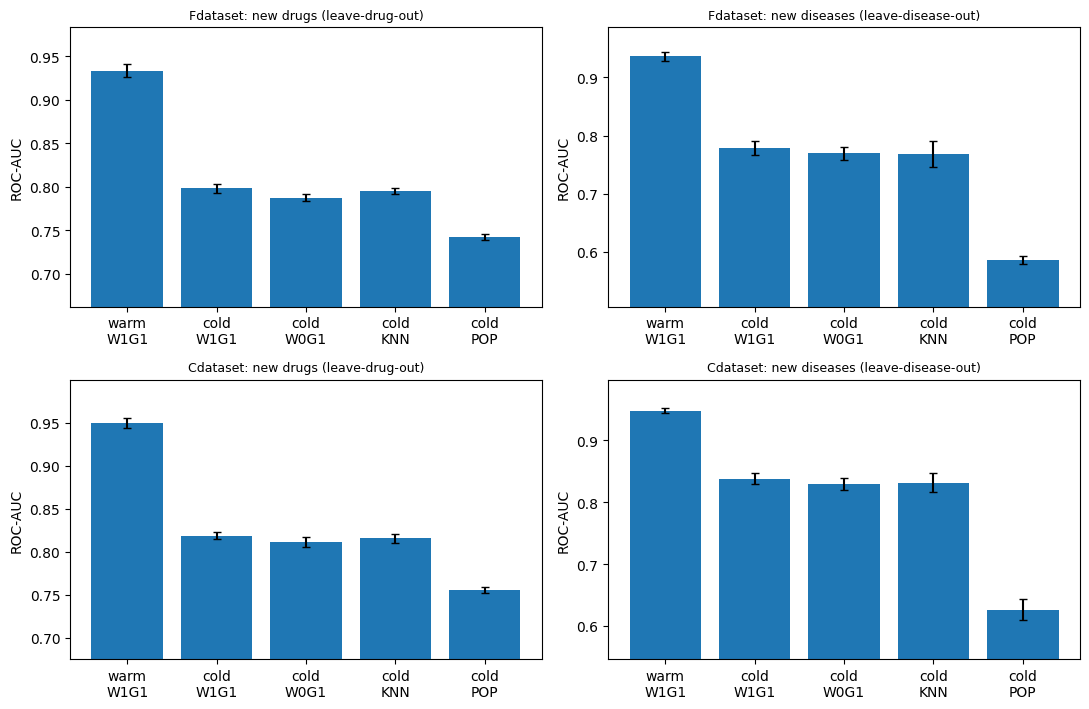

In [7]:
AX = {0: "new drugs (leave-drug-out)", 1: "new diseases (leave-disease-out)"}
for tag, D in LOADED.items():
    for axis in (0, 1):
        df = RES[(RES.task == "RH1") & (RES.dataset == tag) & (RES.axis == axis)]
        if df.empty: continue
        T = seed_pivot(df[df.cond != "stat"], ["cond", "method"]).dropna()
        best = "cold_KNN" if T["cold_KNN"].mean() >= T["cold_POP"].mean() else "cold_POP"      # strongest baseline on these splits (post hoc, conservative)
        drop = T["warm_W1G1"] - T["cold_W1G1"]; margin = T["cold_W1G1"] - T[best]
        sd_, sm_ = pstats(drop), pstats(margin)
        print("=" * 110); print(f"RH1 | {D.name} | {AX[axis]} | strongest baseline: {best.replace('cold_','')}")
        display(pd.DataFrame({"mean AUC": T.mean(), "sd over seeds": T.std(ddof=1)}).round(4).T)
        display(pd.DataFrame([crow("warm - cold (WNMFDDA)  [drop]", drop), crow(f"cold WNMFDDA - {best.replace('cold_','')}  [margin]", margin),
                              crow("cold WNMFDDA - popularity", T["cold_W1G1"] - T["cold_POP"]), crow("cold WNMFDDA - tuned kNN", T["cold_W1G1"] - T["cold_KNN"]),
                              crow("cold WNMFDDA - WKNN-only (K=5)", T["cold_W1G1"] - T["cold_WKNN_ONLY"]),
                              crow("cold WNMFDDA - graph-only (no WKNN)  [WKNN contribution]", T["cold_W1G1"] - T["cold_W0G1"])]).set_index("contrast").round(4))
        st = df[df.cond == "stat"][["sup_pos", "sup_neg"]].mean()
        print(f"neighbour support (top-5, cold): {st.sup_pos:.1%} of held-out positives vs {st.sup_neg:.1%} of negatives")
        sup_a = sd_["mean"] >= RH1_DROP_MIN and sm_["ci_lo"] < RH1_MARGIN
        fal_a = sd_["mean"] < RH1_DROP_FALSIFY or sm_["ci_lo"] > RH1_MARGIN
        sup_s = sd_["ci_lo"] >= RH1_DROP_MIN and sm_["ci_hi"] < RH1_MARGIN
        fal_s = sd_["ci_hi"] < RH1_DROP_FALSIFY or sm_["ci_lo"] > RH1_MARGIN
        key = ("RH1", D.name, AX[axis])
        VERDICT[key] = dict(as_stated=vstr(sup_a, fal_a), strict=vstr(sup_s, fal_s),
                            evidence=f"drop={sd_['mean']:+.3f} [{sd_['ci_lo']:+.3f},{sd_['ci_hi']:+.3f}]; margin over {best.replace('cold_','')}={sm_['mean']:+.3f} [{sm_['ci_lo']:+.3f},{sm_['ci_hi']:+.3f}]")
        PRIMARY[key] = dict(test="IUT: drop > 0.10 AND margin < 0.05", p=max(one_sided_p(drop, RH1_DROP_MIN, "gt"), one_sided_p(margin, RH1_MARGIN, "lt")))
        print(f"RH1 verdict [{D.name}, {AX[axis]}]: as stated = {VERDICT[key]['as_stated']} | strict = {VERDICT[key]['strict']}  |  {VERDICT[key]['evidence']}")
        if axis == 0:
            p = PILOT["RH1"]["LDO"]; print(f"pilot (supplied): cold {p['W1G1']} vs warm {p['warm']}, popularity {p['POP']}, tuned kNN {p['KNN']}")
        else:
            p = PILOT["RH1"]["LDiO"]; print(f"pilot (supplied): cold {p['W1G1']}, tuned kNN {p['KNN']}")

# figure
fig, axs = plt.subplots(len(LOADED), 2, figsize=(11, 3.6 * len(LOADED)), squeeze=False)
for i, (tag, D) in enumerate(LOADED.items()):
    for j, axis in enumerate((0, 1)):
        df = RES[(RES.task == "RH1") & (RES.dataset == tag) & (RES.axis == axis) & (RES.cond != "stat")]
        if df.empty: continue
        T = seed_pivot(df, ["cond", "method"]).dropna()
        cols = ["warm_W1G1", "cold_W1G1", "cold_W0G1", "cold_KNN", "cold_POP"]
        mu, ci = T[cols].mean(), T[cols].sem() * stats.t.ppf(0.975, max(len(T) - 1, 1))
        axs[i, j].bar([c.replace("_", "\n") for c in cols], mu.values, yerr=ci.values, capsize=3)
        axs[i, j].set_ylim(max(0.4, mu.min() - 0.08), min(1.0, mu.max() + 0.05)); axs[i, j].set_ylabel("ROC-AUC"); axs[i, j].set_title(f"{D.name}: {AX[axis]}", fontsize=9)
plt.tight_layout(); plt.show()

In [8]:
# ---- L: how much of a new drug's score vector lies in the span of its top-5 neighbours' profiles? (seed 0, fold 0, leave-drug-out)
rows = []
for tag, D in LOADED.items():
    sp = entity_split(D, 0, 0, 0); Yc = sp.Ycold
    Sc, _ = wnmfdda_scores(Yc, D, True, seed=fit_seed(0, 0)); Yp = wknn_reconstruct(Yc, D)[0]
    el = Yc.sum(1) > 0; elig_idx = np.flatnonzero(el); rng = np.random.default_rng(0)
    def energy(idx, Mx, s, nrm):
        X = Mx[idx].T; coef = np.linalg.lstsq(X, s, rcond=None)[0]; fit = X @ coef
        return float(fit @ fit / nrm)
    nb_raw, nb_yp, rnd = [], [], []
    for i in sp.held:
        s = Sc[i]; nrm = float(s @ s)
        if nrm <= 0: continue
        order = D.ordR[i]; nb = order[el[order]][:PAPER["K"]]
        nb_raw.append(energy(nb, Yc, s, nrm)); nb_yp.append(energy(nb, Yp, s, nrm))
        rnd.append(energy(rng.choice(elig_idx, PAPER["K"], replace=False), Yc, s, nrm))
    rows.append(dict(dataset=D.name, new_drugs=len(nb_raw), span_energy_top5_raw_profiles=np.median(nb_raw), span_energy_top5_Yprime_profiles=np.median(nb_yp), span_energy_5_random_drugs=np.median(rnd)))
display(pd.DataFrame(rows).round(3))
print("span energy = ||projection of the score vector onto the span||^2 / ||score||^2 (median over new drugs). Close to 1 for the neighbours and clearly lower for random drugs supports the 'scores live in the neighbours' span' mechanism; the random-drug column shows what a trivial span captures.")

,dataset,new_drugs,span_energy_top5_raw_profiles,span_energy_top5_Yprime_profiles,span_energy_5_random_drugs
0,Fdataset,119,0.843,0.895,0.033
1,Cdataset,133,0.874,0.922,0.018


span energy = ||projection of the score vector onto the span||^2 / ||score||^2 (median over new drugs). Close to 1 for the neighbours and clearly lower for random drugs supports the 'scores live in the neighbours' span' mechanism; the random-drug column shows what a trivial span captures.


---
# RH2 — The advantage collapses as data gets sparser

> *WNMFDDA's edge over simple methods needs the benchmark's density.*

### E — Equations
WKNN draws on about $2K$ neighbours (K drug-side, K disease-side), each informative with probability roughly proportional to the kept fraction $f$ of the positives. The factorization fits about $f\cdot|Y^+|$ observed entries with $k(n+m)$ parameters:

$$\underbrace{k\,(n+m)}_{\approx 1.45\times10^{5}\ \text{for Fdataset}}\ \text{parameters}\quad\text{vs}\quad f\cdot|Y^+|\ \text{observed positives}.$$

The ratio of parameters to observations grows as $1/f$.

### P — Proposition
As $f$ shrinks, WNMFDDA's AUC falls steeply and its margin over the best simple baseline shrinks to within the equivalence margin $\delta=0.01$.

### Q — Quantifiable prediction (decision rule fixed in advance)
Keep a nested random fraction $f\in\{100\%,50\%,25\%,10\%,5\%\}$ of the *training* positives (held-out test positives and the candidate set are unchanged; dropped positives are neither test positives nor negatives). Compare WNMFDDA with WKNN-only (K = 5), a dev-tuned kNN, and popularity; the best baseline at each density is the one with the highest mean AUC there.
* **SUPPORTED** if AUC(25 %) is at least 0.10 below AUC(100 %) **and** the gain over the best baseline at the sparsest density is below δ.
* **FALSIFIED** if the gain stays above δ at every density.
* Pilot reference (supplied): AUC 0.919 / 0.851 / 0.758 / 0.648 / 0.559 with gains +0.054 / +0.059 / +0.046 / +0.028 / +0.004.

### V — Verification
`N_FOLDS` folds × `N_SEEDS` seeds × densities, both datasets; kNN re-tuned on the thinned training matrix at every density.

### L — Link to predictive consequences
Real repositioning data is sparser than 1 % density, so a collapsing gain would mean the headline AUC overstates what the model delivers there. Thinning here is uniformly random; real sparsity is usually structured (a few well-studied drugs and diseases), which this test does not model.

In [9]:
def rh2_unit(D, seed, fold, f):
    sp = pair_split(D, seed, fold); Yt = thin_train(sp.Ytr, f, seed, fold)
    base = dict(task="RH2", dataset=D.tag, seed=seed, fold=fold, dens=f); rows = []
    Sc, it = wnmfdda_scores(Yt, D, True, seed=fit_seed(seed, fold))
    Yp, Yr, Yd = wknn_reconstruct(Yt, D); sup = ((Yr + Yd) / 2 > 0).ravel()
    rows.append(dict(base, method="W1G1", n_iter=it, n_train_pos=int(Yt.sum()), sup_pos=float(sup[sp.pos].mean()),
                     elig_drug=float((Yt.sum(1) > 0).mean()), elig_dis=float((Yt.sum(0) > 0).mean()), **metrics(Sc, sp.pos, sp.neg)))
    rows.append(dict(base, method="WKNN_ONLY", **metrics(Yp, sp.pos, sp.neg)))
    prm, dev = tune_knn(Yt, D, (seed, fold, int(f * 1000), 12), "pair")
    rows.append(dict(base, method="KNN", params=str(prm), dev_auc=dev, **metrics(knn_score(Yt, D, *prm), sp.pos, sp.neg)))
    rows.append(dict(base, method="POP", **metrics(pop_product(Yt), sp.pos, sp.neg)))
    return rows

tasks = [(f"RH2|{t}|{s}|{fo}|{f}", dict(D=D, seed=s, fold=fo, f=f))
         for t, D in LOADED.items() for s in SEEDS for fo in range(N_FOLDS) for f in DENS]
run_units(rh2_unit, tasks, "RH2")

  [RH2] 27 units done (60s)
  [RH2] 56 units done (123s)
  [RH2] 84 units done (184s)
  [RH2] 111 units done (245s)
  [RH2] 135 units done (306s)
  [RH2] 154 units done (367s)
  [RH2] 173 units done (429s)
  [RH2] 192 units done (490s)
  [RH2] 211 units done (551s)
  [RH2] 231 units done (615s)
  [RH2] finished: 250 new units in 674s (rows cached: 1800)


RH2 | Fdataset


,WNMFDDA,WKNN_ONLY,KNN_tuned,POP,best_baseline,gain,gain_ci_lo,gain_ci_hi,pilot_AUC,pilot_gain,train_positives,params_per_obs,test_pos_supported,drugs_with_data,diseases_with_data,frac_fits_at_iter_cap
density,,,,,,,,,,,,,,,,
1.00,0.9244,0.8093,0.8890,0.6955,KNN,0.0354,0.0320,0.0387,0.919,0.054,1546.4,93.7403,0.6596,0.9327,0.9311,0.0
0.50,0.8544,0.7307,0.8333,0.6482,KNN,0.0211,0.0141,0.0282,0.851,0.059,773.4,187.4321,0.4974,0.6904,0.7300,0.0
0.25,0.7806,0.6626,0.7652,0.6002,KNN,0.0155,0.0071,0.0239,0.758,0.046,386.4,375.1553,0.3556,0.4507,0.5365,0.0
0.10,0.7049,0.6030,0.6921,0.5462,KNN,0.0128,0.0008,0.0248,0.648,0.028,155.0,935.2258,0.2315,0.2232,0.3145,0.0
0.05,0.6530,0.5688,0.6282,0.5193,KNN,0.0248,0.0094,0.0401,0.559,0.004,77.0,1882.5974,0.1622,0.1196,0.1882,0.0


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
AUC(100%) - AUC(25%),5,0.1437,0.1398,0.1477,0.1388,0.1467
gain over best baseline at 5%,5,0.0248,0.0094,0.0401,0.0112,0.0386


RH2 verdict [Fdataset]: as stated = FALSIFIED | strict = INCONCLUSIVE  |  AUC drop 100%->25% = +0.144 [+0.140,+0.148]; gain at 5% = +0.0248 [+0.0094,+0.0401]; gain above delta at 2/5 densities (strict)
RH2 | Cdataset


,WNMFDDA,WKNN_ONLY,KNN_tuned,POP,best_baseline,gain,gain_ci_lo,gain_ci_hi,pilot_AUC,pilot_gain,train_positives,params_per_obs,test_pos_supported,drugs_with_data,diseases_with_data,frac_fits_at_iter_cap
density,,,,,,,,,,,,,,,,
1.00,0.9426,0.8441,0.9181,0.7298,KNN,0.0245,0.0235,0.0256,0.919,0.054,2025.6,84.6761,0.7160,0.9376,0.9255,0.0
0.50,0.8875,0.7713,0.8704,0.6847,KNN,0.0171,0.0145,0.0197,0.851,0.059,1012.6,169.3857,0.5685,0.7155,0.7163,0.0
0.25,0.8216,0.6986,0.8073,0.6286,KNN,0.0143,0.0077,0.0209,0.758,0.046,506.0,338.9723,0.4205,0.4826,0.5249,0.0
0.10,0.7427,0.6260,0.7136,0.5622,KNN,0.0291,0.0114,0.0468,0.648,0.028,202.6,846.5943,0.2728,0.2436,0.3028,0.0
0.05,0.6931,0.5849,0.6500,0.5283,KNN,0.0430,0.0253,0.0608,0.559,0.004,101.0,1698.2178,0.1896,0.1344,0.1839,0.0


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
AUC(100%) - AUC(25%),5,0.1211,0.1152,0.1269,0.1165,0.1275
gain over best baseline at 5%,5,0.0430,0.0253,0.0608,0.0251,0.0606


RH2 verdict [Cdataset]: as stated = FALSIFIED | strict = INCONCLUSIVE  |  AUC drop 100%->25% = +0.121 [+0.115,+0.127]; gain at 5% = +0.0430 [+0.0253,+0.0608]; gain above delta at 4/5 densities (strict)


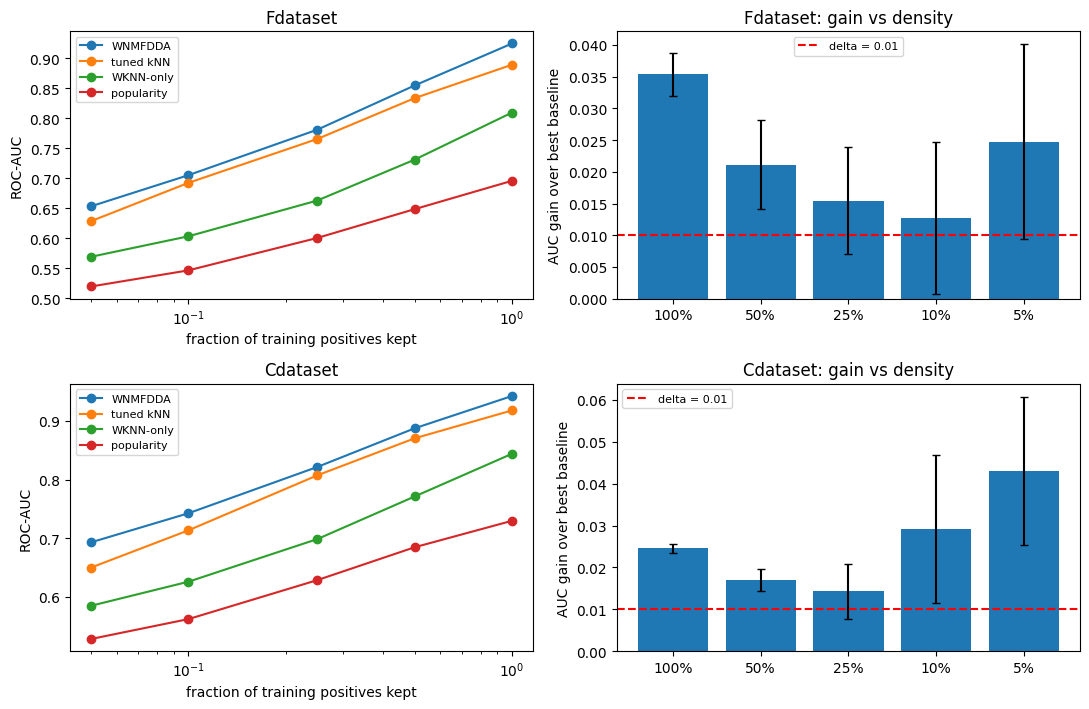

In [10]:
BASES = ["WKNN_ONLY", "KNN", "POP"]
for tag, D in LOADED.items():
    df = RES[(RES.task == "RH2") & (RES.dataset == tag)]
    if df.empty: continue
    rows, gains, aucw = [], {}, {}
    for f in DENS:
        d = df[np.isclose(df.dens, f)]
        if d.empty: continue
        T = d.groupby(["seed", "method"])["auc"].mean().unstack("method").dropna()
        best = T[BASES].mean().idxmax(); g = T["W1G1"] - T[best]; gains[f] = g; aucw[f] = T["W1G1"]
        s = pstats(g); w = d[d.method == "W1G1"]
        rows.append(dict(density=f, WNMFDDA=T.W1G1.mean(), WKNN_ONLY=T.WKNN_ONLY.mean(), KNN_tuned=T.KNN.mean(), POP=T.POP.mean(), best_baseline=best,
                         gain=s["mean"], gain_ci_lo=s["ci_lo"], gain_ci_hi=s["ci_hi"], pilot_AUC=PILOT["RH2"].get(f, (np.nan,))[0], pilot_gain=PILOT["RH2"].get(f, (np.nan, np.nan))[1],
                         train_positives=w.n_train_pos.mean(), params_per_obs=PAPER["k"] * (D.n + D.m) / max(w.n_train_pos.mean(), 1),
                         test_pos_supported=w.sup_pos.mean(), drugs_with_data=w.elig_drug.mean(), diseases_with_data=w.elig_dis.mean(),
                         frac_fits_at_iter_cap=(w.n_iter >= MAX_ITER).mean()))
    print("=" * 110); print(f"RH2 | {D.name}"); display(pd.DataFrame(rows).set_index("density").round(4))
    f_lo = min(DENS)
    drop25 = (aucw[1.0] - aucw[0.25]).dropna(); gain5 = gains[f_lo]
    sd_, sg_ = pstats(drop25), pstats(gain5)
    display(pd.DataFrame([crow("AUC(100%) - AUC(25%)", drop25), crow(f"gain over best baseline at {f_lo:.0%}", gain5)]).set_index("contrast").round(4))
    sup_a = sd_["mean"] >= RH2_DROP_MIN and sg_["mean"] < DELTA
    fal_a = all(pstats(g)["mean"] > DELTA for g in gains.values())
    sup_s = sd_["ci_lo"] >= RH2_DROP_MIN and sg_["ci_hi"] < DELTA
    fal_s = all(pstats(g)["ci_lo"] > DELTA for g in gains.values())
    key = ("RH2", D.name, "density sweep")
    VERDICT[key] = dict(as_stated=vstr(sup_a, fal_a), strict=vstr(sup_s, fal_s),
                        evidence=f"AUC drop 100%->25% = {sd_['mean']:+.3f} [{sd_['ci_lo']:+.3f},{sd_['ci_hi']:+.3f}]; gain at {f_lo:.0%} = {sg_['mean']:+.4f} [{sg_['ci_lo']:+.4f},{sg_['ci_hi']:+.4f}]; gain above delta at {sum(pstats(g)['ci_lo']>DELTA for g in gains.values())}/{len(gains)} densities (strict)")
    PRIMARY[key] = dict(test="IUT: AUC drop(25%) > 0.10 AND gain(sparsest) < 0.01", p=max(one_sided_p(drop25, RH2_DROP_MIN, "gt"), one_sided_p(gain5, DELTA, "lt")))
    print(f"RH2 verdict [{D.name}]: as stated = {VERDICT[key]['as_stated']} | strict = {VERDICT[key]['strict']}  |  {VERDICT[key]['evidence']}")

fig, axs = plt.subplots(len(LOADED), 2, figsize=(11, 3.6 * len(LOADED)), squeeze=False)
for i, (tag, D) in enumerate(LOADED.items()):
    df = RES[(RES.task == "RH2") & (RES.dataset == tag)]
    if df.empty: continue
    for meth, lab in (("W1G1", "WNMFDDA"), ("KNN", "tuned kNN"), ("WKNN_ONLY", "WKNN-only"), ("POP", "popularity")):
        m_ = df[df.method == meth].groupby(["dens", "seed"])["auc"].mean().groupby("dens").mean()
        axs[i, 0].plot(m_.index, m_.values, "o-", label=lab)
    axs[i, 0].set_xscale("log"); axs[i, 0].set_xlabel("fraction of training positives kept"); axs[i, 0].set_ylabel("ROC-AUC"); axs[i, 0].set_title(D.name); axs[i, 0].legend(fontsize=8)
    gs = []
    for f in DENS:
        d = df[np.isclose(df.dens, f)]; T = d.groupby(["seed", "method"])["auc"].mean().unstack("method").dropna()
        gs.append(pstats(T["W1G1"] - T[T[BASES].mean().idxmax()]))
    xs = np.arange(len(DENS)); mu = np.array([g["mean"] for g in gs]); err = np.array([g["mean"] - g["ci_lo"] for g in gs])
    axs[i, 1].bar(xs, mu, yerr=np.nan_to_num(err), capsize=3); axs[i, 1].axhline(DELTA, ls="--", c="r", label=f"delta = {DELTA}")
    axs[i, 1].set_xticks(xs); axs[i, 1].set_xticklabels([f"{f:.0%}" for f in DENS]); axs[i, 1].set_ylabel("AUC gain over best baseline"); axs[i, 1].set_title(f"{D.name}: gain vs density"); axs[i, 1].legend(fontsize=8)
plt.tight_layout(); plt.show()

---
# RH3 — Most of the lift is neighbour evidence that a training-free method recovers

> *Most of WNMFDDA's gain over popularity is information a training-free neighbour average already provides.*

### E — Equations
From Eqs. 1–5, $Y_{rd}=(Y^R+Y^D)/2$ is zero for a pair $(i,\ell)$ unless some top-$K$ neighbour of drug $i$ carries disease $\ell$, or some top-$K$ neighbour of disease $\ell$ carries drug $i$. Define **neighbour support** as $Y_{rd,i\ell}>0$. A pair without support is scored 0 by WKNN, so WKNN cannot rank it above chance among the other unsupported pairs. The lift over popularity is

$$\text{lift share}(m)=\frac{\text{AUC}(m)-\text{AUC}(\text{popularity})}{\text{AUC}(\text{WNMFDDA})-\text{AUC}(\text{popularity})},\qquad \text{gap}(m)=\text{AUC}(\text{WNMFDDA})-\text{AUC}(m).$$

### P — Proposition
A dev-tuned method with no iterative training (neighbour average or graph diffusion) recovers most of the lift. The factorization then adds mainly the ranking of *unsupported* positives, which is a smaller share of the total.

### Q — Quantifiable prediction (decision rule fixed in advance)
On held-out positives with all unknown pairs as negatives, compute: the share of positives and of negatives with neighbour support; AUC separately on supported and unsupported positives; a one-bit "is supported" baseline; WKNN-only at the paper's K = 5; and dev-tuned kNN, graph diffusion and truncated SVD.
* **SUPPORTED** if the dev-selected training-free method (kNN or diffusion, chosen by inner-split AUC) recovers ≥ 70 % of the lift **and** sits < 0.06 below WNMFDDA.
* **FALSIFIED** if no simple method, including truncated SVD and graph diffusion, gets within 0.06.
* Pilot reference (supplied): support 64 % of positives vs 6 % of negatives; WNMFDDA AUC 0.986 supported / 0.801 unsupported; WKNN-only 0.47 on unsupported; one-bit 0.784; tuned kNN 0.865 vs WNMFDDA 0.919 vs popularity 0.708 (74 % of the lift); WKNN-only at K = 5 0.798.

### V — Verification
Warm pair-held-out CV, `N_FOLDS` × `N_SEEDS`, both datasets. Every simple method is tuned on an inner dev split of the training matrix and compared on identical test pairs.

### L — Link to predictive consequences
**What it would not show:** WNMFDDA still reaching about 0.80 AUC on unsupported positives, against about 0.65 for popularity, means the factorization is not redundant. The claim concerns how much of the lift needs it. The lift share depends on the popularity floor, so the absolute gap is reported beside it.

In [11]:
def rh3_unit(D, seed, fold):
    sp = pair_split(D, seed, fold); Ytr = sp.Ytr
    base = dict(task="RH3", dataset=D.tag, seed=seed, fold=fold); rows = []
    Yp, Yr, Yd = wknn_reconstruct(Ytr, D); sup = ((Yr + Yd) / 2 > 0).ravel()
    sp_pos, sp_neg = sup[sp.pos], sup[sp.neg]
    sc, par, dev = {}, {}, {}
    sc["POP"] = pop_product(Ytr); sc["WKNN_ONLY"] = Yp; sc["ONEBIT"] = sup.reshape(Ytr.shape).astype(float)
    prm, dev["KNN"] = tune_knn(Ytr, D, (seed, fold, 21), "pair"); sc["KNN"] = knn_score(Ytr, D, *prm); par["KNN"] = prm
    prm, dev["DIFF"] = tune_diff(Ytr, D, (seed, fold, 22), "pair"); sc["DIFF"] = diffusion_score(Ytr, D, prm); par["DIFF"] = prm
    prm, dev["SVD"] = tune_svd(Ytr, D, (seed, fold, 23), "pair"); sc["SVD"] = svd_score(Yp, prm); par["SVD"] = prm
    sc["W1G1"], it = wnmfdda_scores(Ytr, D, True, seed=fit_seed(seed, fold))
    for m, S in sc.items():
        s = S.ravel(); nss = np.sort(s[sp.neg]); ps = s[sp.pos]
        rows.append(dict(base, method=m, auc=auc_vs(ps, nss), auc_sup=auc_vs(ps[sp_pos], nss), auc_unsup=auc_vs(ps[~sp_pos], nss),
                         aupr=float(average_precision_score(np.r_[np.ones(len(ps)), np.zeros(len(nss))], np.r_[ps, s[sp.neg]])),
                         dev_auc=dev.get(m, np.nan), params=str(par.get(m, "")), n_iter=it if m == "W1G1" else np.nan))
    rows.append(dict(base, method="STAT", sup_pos=float(sp_pos.mean()), sup_neg=float(sp_neg.mean()), n_pos=len(sp.pos)))
    return rows

tasks = [(f"RH3|{t}|{s}|{fo}", dict(D=D, seed=s, fold=fo)) for t, D in LOADED.items() for s in SEEDS for fo in range(N_FOLDS)]
run_units(rh3_unit, tasks, "RH3")

  [RH3] 21 units done (63s)
  [RH3] 36 units done (125s)
  [RH3] 49 units done (187s)
  [RH3] finished: 50 new units in 191s (rows cached: 2200)


RH3 | Fdataset
neighbour support (top-5): 66.0% of held-out positives vs 6.5% of negatives   (pilot: 64% vs 6%)


,AUC,AUC_supported,AUC_unsupported,AUPR,dev_AUC,lift_share,lift_lo,gap_to_WNMFDDA,gap_lo,gap_hi
method,,,,,,,,,,
POP,0.6955,0.7477,0.5948,0.0095,NaN,0.0000,0.0000,0.2289,0.2238,0.2339
WKNN_ONLY,0.8093,0.9856,0.4676,0.1294,NaN,0.4970,0.4828,0.1151,0.1123,0.1179
ONEBIT,0.7974,0.9676,0.4676,0.0146,NaN,0.4452,0.4308,0.1270,0.1240,0.1299
KNN,0.8894,0.9864,0.7015,0.1297,0.8754,0.8471,0.8272,0.0350,0.0305,0.0394
DIFF,0.8814,0.9849,0.6811,0.1206,0.8690,0.8123,0.7961,0.0429,0.0393,0.0466
SVD,0.8710,0.9421,0.7333,0.2482,0.8480,0.7668,0.7564,0.0534,0.0518,0.0549
W1G1,0.9244,0.9904,0.7965,0.2822,NaN,NaN,NaN,NaN,NaN,NaN


pilot (supplied): WNMFDDA 0.919 / supported 0.986 / unsupported 0.801; WKNN-only unsupported 0.47; one-bit 0.784; tuned kNN 0.865; popularity 0.708; WKNN-only K=5 0.798
dev-selected training-free method: KNN (dev AUC 0.8754)


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
WNMFDDA - popularity on UNSUPPORTED positives,5,0.2017,0.1922,0.2113,0.1903,0.2102
WNMFDDA - best free method on UNSUPPORTED positives,5,0.0950,0.0820,0.1079,0.0842,0.1085
"WNMFDDA - WKNN-only(K=5), pooled",5,0.1151,0.1123,0.1179,0.1116,0.1177
"WNMFDDA - tuned kNN, pooled",5,0.0350,0.0305,0.0394,0.0314,0.0394


RH3 verdict [Fdataset]: as stated = SUPPORTED | strict = SUPPORTED  |  KNN: lift share 84.7% [82.7%,86.7%], gap +0.035 [+0.031,+0.039]; smallest gap over all simple methods = +0.035
RH3 | Cdataset
neighbour support (top-5): 71.6% of held-out positives vs 5.2% of negatives   (pilot: 64% vs 6%)


,AUC,AUC_supported,AUC_unsupported,AUPR,dev_AUC,lift_share,lift_lo,gap_to_WNMFDDA,gap_lo,gap_hi
method,,,,,,,,,,
POP,0.7298,0.7846,0.5918,0.0106,NaN,0.0000,0.0000,0.2128,0.2086,0.2170
WKNN_ONLY,0.8441,0.9909,0.4740,0.2273,NaN,0.5369,0.5169,0.0985,0.0955,0.1015
ONEBIT,0.8320,0.9740,0.4740,0.0187,NaN,0.4800,0.4592,0.1106,0.1076,0.1136
KNN,0.9180,0.9918,0.7320,0.2362,0.9020,0.8843,0.8763,0.0246,0.0229,0.0263
DIFF,0.9118,0.9905,0.7133,0.1900,0.8968,0.8552,0.8453,0.0308,0.0287,0.0329
SVD,0.8881,0.9432,0.7494,0.3459,0.8719,0.7437,0.7307,0.0545,0.0516,0.0575
W1G1,0.9426,0.9931,0.8151,0.4018,NaN,NaN,NaN,NaN,NaN,NaN


pilot (supplied): WNMFDDA 0.919 / supported 0.986 / unsupported 0.801; WKNN-only unsupported 0.47; one-bit 0.784; tuned kNN 0.865; popularity 0.708; WKNN-only K=5 0.798
dev-selected training-free method: KNN (dev AUC 0.9020)


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
WNMFDDA - popularity on UNSUPPORTED positives,5,0.2234,0.2124,0.2343,0.2092,0.2317
WNMFDDA - best free method on UNSUPPORTED positives,5,0.0831,0.0757,0.0905,0.0765,0.0925
"WNMFDDA - WKNN-only(K=5), pooled",5,0.0985,0.0955,0.1015,0.0947,0.1008
"WNMFDDA - tuned kNN, pooled",5,0.0246,0.0229,0.0263,0.0228,0.0266


RH3 verdict [Cdataset]: as stated = SUPPORTED | strict = SUPPORTED  |  KNN: lift share 88.4% [87.6%,89.2%], gap +0.025 [+0.023,+0.026]; smallest gap over all simple methods = +0.025


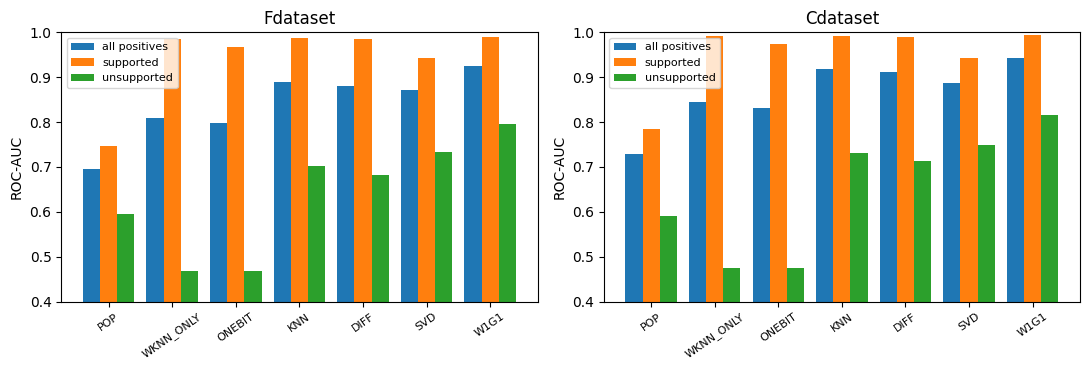

In [12]:
SIMPLE = ["POP", "WKNN_ONLY", "ONEBIT", "KNN", "DIFF", "SVD"]; TF = ["KNN", "DIFF"]
for tag, D in LOADED.items():
    df = RES[(RES.task == "RH3") & (RES.dataset == tag)]
    if df.empty: continue
    st = df[df.method == "STAT"][["sup_pos", "sup_neg"]].mean(); d = df[df.method != "STAT"]
    P = {v: d.groupby(["seed", "method"])[v].mean().unstack("method").dropna() for v in ("auc", "auc_sup", "auc_unsup", "aupr")}
    A = P["auc"]; dev_mean = d.groupby("method")["dev_auc"].mean()
    best_free = dev_mean[TF].idxmax()
    lift = {m: (A[m] - A["POP"]) / (A["W1G1"] - A["POP"]) for m in SIMPLE}; gap = {m: A["W1G1"] - A[m] for m in SIMPLE}
    print("=" * 110); print(f"RH3 | {D.name}")
    print(f"neighbour support (top-{PAPER['K']}): {st.sup_pos:.1%} of held-out positives vs {st.sup_neg:.1%} of negatives   (pilot: {PILOT['RH3']['sup_pos']:.0%} vs {PILOT['RH3']['sup_neg']:.0%})")
    rows = []
    for m in ["POP", "WKNN_ONLY", "ONEBIT", "KNN", "DIFF", "SVD", "W1G1"]:
        r = dict(method=m, AUC=A[m].mean(), AUC_supported=P["auc_sup"][m].mean(), AUC_unsupported=P["auc_unsup"][m].mean(), AUPR=P["aupr"][m].mean(), dev_AUC=dev_mean.get(m, np.nan))
        if m in SIMPLE:
            sl, sg = pstats(lift[m]), pstats(gap[m])
            r.update(lift_share=sl["mean"], lift_lo=sl["ci_lo"], gap_to_WNMFDDA=sg["mean"], gap_lo=sg["ci_lo"], gap_hi=sg["ci_hi"])
        rows.append(r)
    display(pd.DataFrame(rows).set_index("method").round(4))
    pl = PILOT["RH3"]
    print(f"pilot (supplied): WNMFDDA {pl['W1G1']} / supported {pl['W1G1_sup']} / unsupported {pl['W1G1_unsup']}; WKNN-only unsupported {pl['WKNN_ONLY_unsup']}; one-bit {pl['ONEBIT']}; "
          f"tuned kNN {pl['KNN']}; popularity {pl['POP']}; WKNN-only K=5 {pl['WKNN_ONLY']}")
    print(f"dev-selected training-free method: {best_free} (dev AUC {dev_mean[best_free]:.4f})")
    u = P["auc_unsup"]; display(pd.DataFrame([crow("WNMFDDA - popularity on UNSUPPORTED positives", u["W1G1"] - u["POP"]), crow("WNMFDDA - best free method on UNSUPPORTED positives", u["W1G1"] - u[best_free]),
                                              crow("WNMFDDA - WKNN-only(K=5), pooled", gap["WKNN_ONLY"]), crow("WNMFDDA - tuned kNN, pooled", gap["KNN"])]).set_index("contrast").round(4))
    lf, gf = pstats(lift[best_free]), pstats(gap[best_free])
    sup_a = lf["mean"] >= RH3_LIFT_MIN and gf["mean"] < RH3_GAP_MAX
    fal_a = all(pstats(gap[m])["mean"] >= RH3_GAP_MAX for m in SIMPLE)
    sup_s = lf["ci_lo"] >= RH3_LIFT_MIN and gf["ci_hi"] < RH3_GAP_MAX
    fal_s = all(pstats(gap[m])["ci_lo"] >= RH3_GAP_MAX for m in SIMPLE)
    key = ("RH3", D.name, "pair-held-out CV")
    VERDICT[key] = dict(as_stated=vstr(sup_a, fal_a), strict=vstr(sup_s, fal_s),
                        evidence=f"{best_free}: lift share {lf['mean']:.1%} [{lf['ci_lo']:.1%},{lf['ci_hi']:.1%}], gap {gf['mean']:+.3f} [{gf['ci_lo']:+.3f},{gf['ci_hi']:+.3f}]; smallest gap over all simple methods = {min(pstats(gap[m])['mean'] for m in SIMPLE):+.3f}")
    PRIMARY[key] = dict(test="IUT: lift share > 0.70 AND gap < 0.06 (dev-selected free method)", p=max(one_sided_p(lift[best_free], RH3_LIFT_MIN, "gt"), one_sided_p(gap[best_free], RH3_GAP_MAX, "lt")))
    print(f"RH3 verdict [{D.name}]: as stated = {VERDICT[key]['as_stated']} | strict = {VERDICT[key]['strict']}  |  {VERDICT[key]['evidence']}")

fig, axs = plt.subplots(1, len(LOADED), figsize=(11, 3.8), squeeze=False)
for ax, (tag, D) in zip(axs[0], LOADED.items()):
    d = RES[(RES.task == "RH3") & (RES.dataset == tag) & (RES.method != "STAT")]
    if d.empty: continue
    order = ["POP", "WKNN_ONLY", "ONEBIT", "KNN", "DIFF", "SVD", "W1G1"]; w = 0.27
    for k, (col, lab) in enumerate((("auc", "all positives"), ("auc_sup", "supported"), ("auc_unsup", "unsupported"))):
        v = d.groupby(["method", "seed"])[col].mean().groupby("method").mean().reindex(order)
        ax.bar(np.arange(len(order)) + (k - 1) * w, v.values, w, label=lab)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=35, fontsize=8); ax.set_ylim(0.4, 1.0); ax.set_ylabel("ROC-AUC"); ax.set_title(D.name); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

---
# Consolidated evidence: directional p-values, Holm correction and verdicts
Every primary test is an intersection–union test of the rule's two conditions, so **a small p-value means the rejection hypothesis is supported** (all three, both datasets, both axes for RH1). Holm correction covers all primary tests together. A p-value of exactly 0 or 1 can occur when seed-level values have no variance.

In [13]:
keys = list(PRIMARY)
tab = pd.DataFrame([dict(hypothesis=k[0], dataset=k[1], setting=k[2], test=PRIMARY[k]["test"], p_raw=PRIMARY[k]["p"]) for k in keys])
tab["p_holm"] = holm(tab.p_raw.values)
tab["small p means"] = "rejection hypothesis supported"
display(tab.round(4))
summ = pd.DataFrame([dict(hypothesis=k[0], dataset=k[1], setting=k[2], verdict_as_stated=VERDICT[k]["as_stated"], verdict_strict=VERDICT[k]["strict"], evidence=VERDICT[k]["evidence"]) for k in keys])
display(summ)
w = RES[(RES.method == "W1G1") & RES.n_iter.notna()]
print(f"share of WNMFDDA fits that stopped at the iteration cap ({MAX_ITER}) instead of converging: {(w.n_iter >= MAX_ITER).mean():.1%}  (see the convergence audit for the AUC sensitivity)")
tab.to_csv(os.path.join(OUT_DIR, f"rh_primary_tests_holm_{PROFILE}.csv"), index=False); summ.to_csv(os.path.join(OUT_DIR, f"rh_verdicts_{PROFILE}.csv"), index=False)
print(f"saved: {RES_PATH} | rh_primary_tests_holm_{PROFILE}.csv | rh_verdicts_{PROFILE}.csv  (in {OUT_DIR})")
print(f"Settings: profile={PROFILE}, seeds={N_SEEDS}, folds={N_FOLDS}, max_iter={MAX_ITER}, delta={DELTA}, ELIG={ELIG}. "
      "Inference is conditional on these two datasets; negatives are unobserved pairs, so AUC and AUPR are low-base-rate estimates.")

,hypothesis,dataset,setting,test,p_raw,p_holm,small p means
0,RH1,Fdataset,new drugs (leave-drug-out),IUT: drop > 0.10 AND margin < 0.05,0.0000,0.0003,rejection hypothesis supported
1,RH1,Fdataset,new diseases (leave-disease-out),IUT: drop > 0.10 AND margin < 0.05,0.0005,0.0019,rejection hypothesis supported
2,RH1,Cdataset,new drugs (leave-drug-out),IUT: drop > 0.10 AND margin < 0.05,0.0003,0.0016,rejection hypothesis supported
3,RH1,Cdataset,new diseases (leave-disease-out),IUT: drop > 0.10 AND margin < 0.05,0.0047,0.0142,rejection hypothesis supported
4,RH2,Fdataset,density sweep,IUT: AUC drop(25%) > 0.10 AND gain(sparsest) < 0.01,0.9718,1.0000,rejection hypothesis supported
5,RH2,Cdataset,density sweep,IUT: AUC drop(25%) > 0.10 AND gain(sparsest) < 0.01,0.9967,1.0000,rejection hypothesis supported
6,RH3,Fdataset,pair-held-out CV,IUT: lift share > 0.70 AND gap < 0.06 (dev-selected free method),0.0000,0.0003,rejection hypothesis supported
7,RH3,Cdataset,pair-held-out CV,IUT: lift share > 0.70 AND gap < 0.06 (dev-selected free method),0.0000,0.0000,rejection hypothesis supported


,hypothesis,dataset,setting,verdict_as_stated,verdict_strict,evidence
0,RH1,Fdataset,new drugs (leave-drug-out),SUPPORTED,SUPPORTED,"drop=+0.135 [+0.129,+0.141]; margin over KNN=+0.003 [-0.002,+0.009]"
1,RH1,Fdataset,new diseases (leave-disease-out),SUPPORTED,SUPPORTED,"drop=+0.158 [+0.150,+0.167]; margin over KNN=+0.009 [-0.004,+0.022]"
2,RH1,Cdataset,new drugs (leave-drug-out),SUPPORTED,SUPPORTED,"drop=+0.131 [+0.122,+0.140]; margin over KNN=+0.003 [-0.001,+0.007]"
3,RH1,Cdataset,new diseases (leave-disease-out),SUPPORTED,SUPPORTED,"drop=+0.110 [+0.104,+0.116]; margin over KNN=+0.007 [-0.000,+0.014]"
4,RH2,Fdataset,density sweep,FALSIFIED,INCONCLUSIVE,"AUC drop 100%->25% = +0.144 [+0.140,+0.148]; gain at 5% = +0.0248 [+0.0094,+0.0401]; gain above delta at 2/5 densities (strict)"
5,RH2,Cdataset,density sweep,FALSIFIED,INCONCLUSIVE,"AUC drop 100%->25% = +0.121 [+0.115,+0.127]; gain at 5% = +0.0430 [+0.0253,+0.0608]; gain above delta at 4/5 densities (strict)"
6,RH3,Fdataset,pair-held-out CV,SUPPORTED,SUPPORTED,"KNN: lift share 84.7% [82.7%,86.7%], gap +0.035 [+0.031,+0.039]; smallest gap over all simple methods = +0.035"
7,RH3,Cdataset,pair-held-out CV,SUPPORTED,SUPPORTED,"KNN: lift share 88.4% [87.6%,89.2%], gap +0.025 [+0.023,+0.026]; smallest gap over all simple methods = +0.025"


share of WNMFDDA fits that stopped at the iteration cap (200) instead of converging: 0.3%  (see the convergence audit for the AUC sensitivity)
saved: /kaggle/working/wnmfdda_rh_results_quick.csv | rh_primary_tests_holm_quick.csv | rh_verdicts_quick.csv  (in /kaggle/working)
Settings: profile=quick, seeds=5, folds=5, max_iter=200, delta=0.01, ELIG=True. Inference is conditional on these two datasets; negatives are unobserved pairs, so AUC and AUPR are low-base-rate estimates.
